## 1. Modelling

In [18]:
# 1. Standard library imports
import importlib
import os

# 2. Third-party imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# 3. Local application imports
from src import config, datautils, predict, preprocess

# Reload local modules to reflect recent edits
importlib.reload(config)
importlib.reload(datautils)
importlib.reload(preprocess)
importlib.reload(predict)

# Import specific functions AFTER reloading the parent module
from src.predict import predict_from_df

We began by establishing baseline performance using the top 5 selected features across several candidate models to compare evaluation metrics. Next, we introduced a custom preprocessing step (`preprocess.FeatureEngineer()`) that appends three domain-informed non-linear features:

* **`f13_sqrt`:** Clipped square root transformation ($\sqrt{\max(x_{13}, 0)}$) to capture diminishing returns.
* **`f13_log`:** Shifted logarithmic transformation ($\log(1 + \max(x_{13}, 0))$) to compress right-skewed variance.
* **`f18_quad`:** Mean-centered quadratic term ($(x_{18} - \bar{x}_{18})^2$) to capture symmetric curvature around the feature's average.

In [9]:
FULL_PATH_TRAIN = os.path.join(config.DATASET_ROOT_PATH, config.DATASET_FILENAME)
FULL_PATH_TEST = os.path.join(config.DATASET_ROOT_PATH, config.TEST_FILENAME)
df_train = pd.read_csv(FULL_PATH_TRAIN)
df_test = pd.read_csv(FULL_PATH_TEST)
X, y = preprocess.get_feature_target(df_train, target_column=config.TARGET_COLUMN)
X_train, X_val, y_train, y_val = preprocess.get_train_val_sets(X, y)

* **Model Selection (Ridge & Lasso):** Regularized linear models were selected over standard Ordinary Least Squares (OLS) to prevent overfitting and improve generalization on the blind test set. By introducing L2 (Ridge) and L1 (Lasso) penalties, the models constrain coefficient magnitudes, reduce variance, and—in the case of Lasso—perform embedded feature selection by shrinking uninformative predictors to zero.
* **Feature Scaling:** StandardScaler was applied to center all features around zero with unit variance. Because regularized linear models (Ridge and Lasso) apply penalties uniformly across coefficients, ensuring identical variance across all predictors is critical so no feature is disproportionately penalized due to its scale or distribution shape.

In [13]:
top_5 = config.TOP_FEATURES
X_base = X_train[top_5].copy()
X_val_base = X_val[top_5].copy()

# 1. Domain/Visual Feature Engineering based on scatterplots
X_eng = X_base.copy()
X_eng["f13_sqrt"] = np.sqrt(np.maximum(X_eng["feature_13"], 0))
X_eng["f13_log"] = np.log1p(np.maximum(X_eng["feature_13"], 0))
X_eng["f18_quad"] = (X_eng["feature_18"] - X_eng["feature_18"].mean()) ** 2

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Compare: Raw Top 5 vs. Poly Degree 2 vs. Custom Engineered + Poly
models = {
    "Linear (Top 5 raw)": make_pipeline(StandardScaler(), RidgeCV()),
    "Poly Deg 2 (Top 5 raw)": make_pipeline(StandardScaler(), PolynomialFeatures(2), RidgeCV()),
    "Poly Deg 3 (Top 5 raw)": make_pipeline(StandardScaler(), PolynomialFeatures(3), RidgeCV()),
    "Custom + Poly Deg 2": make_pipeline(preprocess.FeatureEngineer(), StandardScaler(), PolynomialFeatures(2), RidgeCV()),
}

datasets = {
    "Linear (Top 5 raw)": X_base,
    "Poly Deg 2 (Top 5 raw)": X_base,
    "Poly Deg 3 (Top 5 raw)": X_base,
    "Custom + Poly Deg 2": X_base
}

# Saving the scores of tran and validation sets for each model in a list of dictionaries

results = []

for name, model in models.items():
  cv_res = cross_validate(
      model,
      datasets[name],
      y_train,
      cv=cv,
      scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"},
  )
  r2 = cv_res["test_r2"]
  rmse = -cv_res["test_rmse"]

  # 2. Fit on full training data and evaluate on X_val_base
  model.fit(datasets[name], y_train)
  y_val_pred = model.predict(X_val_base)

  val_r2 = r2_score(y_val, y_val_pred)
  val_rmse = root_mean_squared_error(y_val, y_val_pred)

  # 3. Store row metrics
  results.append({
      "Model": name,
      "CV R2 Mean": r2.mean(),
      "CV R2 Std": r2.std(),
      "Val R2": val_r2,
      "Overfit Gap (CV - Val)": r2.mean() - val_r2,
      "CV RMSE": rmse.mean(),
      "Val RMSE": val_rmse,
  })

results_df = pd.DataFrame(results).sort_values(by="Val R2", ascending=False)

print(results_df.round(5).to_string(index=False))

                 Model  CV R2 Mean  CV R2 Std  Val R2  Overfit Gap (CV - Val)  CV RMSE  Val RMSE
Poly Deg 3 (Top 5 raw)     0.90282    0.02356 0.89679                 0.00603  1.58924   1.52223
   Custom + Poly Deg 2     0.86156    0.02483 0.86522                -0.00366  1.90306   1.73954
Poly Deg 2 (Top 5 raw)     0.83754    0.02826 0.83011                 0.00744  2.06194   1.95302
    Linear (Top 5 raw)     0.68903    0.03319 0.69736                -0.00833  2.86665   2.60665


Using Lasso CV to remove coefficients below 0.05 then using therms on ridge that penalizes less with 50 candidates of alpha.

In [5]:
import numpy as np
import pandas as pd
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

top_5 = ["feature_2", "feature_13", "feature_9", "feature_11", "feature_18"]
X_base = X_train[top_5].copy()

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Native leak-free pipeline: Scale -> Poly(3) -> L1 Selection -> L2 Refit
sparse_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    (
        "selector",
        SelectFromModel(
            estimator=LassoCV(cv=5, max_iter=20000, random_state=42),
            threshold=0.05,
        ),
    ),
    ("model", RidgeCV(alphas=np.logspace(-3, 3, 50))),
])

# Evaluate out-of-fold performance
r2_scores = cross_val_score(sparse_pipe, X_base, y_train, cv=cv, scoring="r2")
rmse_scores = -cross_val_score(
    sparse_pipe, X_base, y_train, cv=cv, scoring="neg_root_mean_squared_error"
)

# Fit once on full dataset to inspect selected terms & final Ridge weights
sparse_pipe.fit(X_base, y_train)
y_val_pred = sparse_pipe.predict(X_val_base)
val_r2 = r2_score(y_val, y_val_pred)
val_rmse = root_mean_squared_error(y_val, y_val_pred)
all_names = sparse_pipe.named_steps["poly"].get_feature_names_out(top_5)
selected_mask = sparse_pipe.named_steps["selector"].get_support()
selected_names = all_names[selected_mask]

final_coefs = pd.Series(
    sparse_pipe.named_steps["model"].coef_,
    index=selected_names,
).sort_values(key=abs, ascending=False)

print(f"Selected {len(selected_names)} / {len(all_names)} polynomial terms:")
display(final_coefs)

comparison_df = pd.DataFrame({
    "Métrica": ["R2", "RMSE"],
    "Train (CV)": [
        f"{r2_scores.mean():.5f} (+/- {r2_scores.std():.5f})",
        f"{rmse_scores.mean():.5f} (+/- {rmse_scores.std():.5f})",
    ],
    "Validation": [
        f"{val_r2:.5f}",
        f"{val_rmse:.5f}",
    ],
    "Gap (CV - Val)": [
        f"{r2_scores.mean() - val_r2:+.5f}",
        f"{rmse_scores.mean() - val_rmse:+.5f}",
    ],
})

display(comparison_df.style.hide(axis="index"))


Selected 20 / 55 polynomial terms:


feature_13                          3.033810
feature_2                           2.681892
feature_9                           2.582589
feature_18^2                        1.750997
feature_11                          1.520144
feature_13^2                       -1.182772
feature_13 feature_9^2             -1.084208
feature_13^2 feature_9             -0.991107
feature_9^2                        -0.868547
feature_9^2 feature_18              0.162728
feature_9 feature_18                0.149936
feature_11^2 feature_18             0.146973
feature_2 feature_11 feature_18     0.134934
feature_2^2 feature_9               0.123846
feature_9 feature_18^2              0.113941
feature_2 feature_9                -0.108922
feature_2 feature_13 feature_9      0.105839
feature_2^3                         0.089400
feature_13 feature_11 feature_18   -0.088219
feature_11^3                        0.018529
dtype: float64

Métrica,Train (CV),Validation,Gap (CV - Val)
R2,0.90603 (+/- 0.02385),0.89690,+0.00913
RMSE,1.56078 (+/- 0.16090),1.52140,+0.03938


In [ ]:
poly = sparse_pipe.named_steps["poly"]
selector = sparse_pipe.named_steps["selector"]
ridge = sparse_pipe.named_steps["model"]

# Get the names of the surviving polynomial terms
all_names = poly.get_feature_names_out(top_5)
selected_names = all_names[selector.get_support()]

intercept = ridge.intercept_
coefs = ridge.coef_

# Format as a readable mathematical equation
terms = [f"{intercept:.4f}"]
for name, weight in zip(selected_names, coefs):
    sign = "+" if weight >= 0 else "-"
    terms.append(f"{sign} {abs(weight):.4f} * ({name})")

print("Equation:\ntarget = " + " ".join(terms))


Standardized Equation:
target = 14.9066 + 2.6819 * (feature_2) + 3.0338 * (feature_13) + 2.5826 * (feature_9) + 1.5201 * (feature_11) - 0.1089 * (feature_2 feature_9) - 1.1828 * (feature_13^2) - 0.8685 * (feature_9^2) + 0.1499 * (feature_9 feature_18) + 1.7510 * (feature_18^2) + 0.0894 * (feature_2^3) + 0.1238 * (feature_2^2 feature_9) + 0.1058 * (feature_2 feature_13 feature_9) + 0.1349 * (feature_2 feature_11 feature_18) - 0.9911 * (feature_13^2 feature_9) - 1.0842 * (feature_13 feature_9^2) - 0.0882 * (feature_13 feature_11 feature_18) + 0.1627 * (feature_9^2 feature_18) + 0.1139 * (feature_9 feature_18^2) + 0.0185 * (feature_11^3) + 0.1470 * (feature_11^2 feature_18)


The final result is a simple, easy-to-interpret equation.

## 2. Evaluation

1. Goodness of Fit: Consistent prediction accuracy across both low and high target values.
2. Residuals: Centered around zero with no discernible patterns, confirming that polynomial and engineered terms captured the underlying non-linearities.
3. Residual Distribution: Symmetrical distribution with no severe skew or extreme outliers.


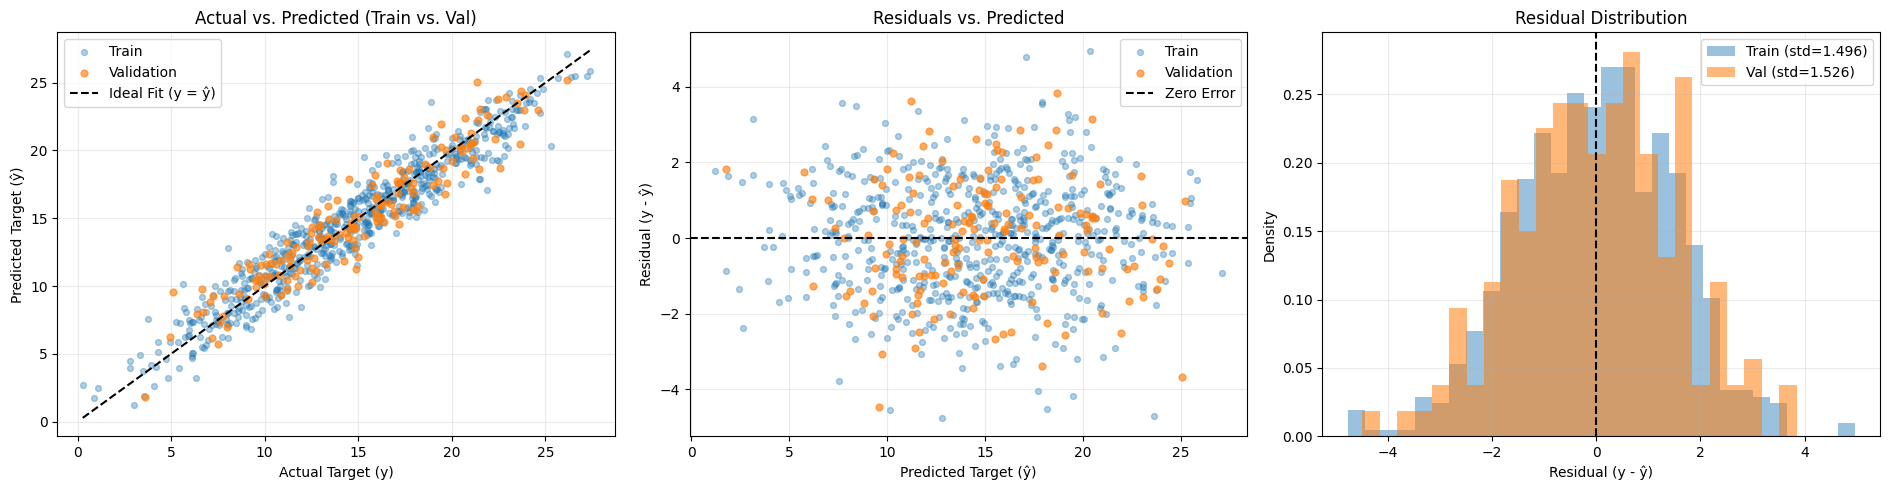

In [20]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

# 1. Generate predictions for both Validation and Test
df_train_pred = pd.read_csv(config.TRAIN_PRED_PATH)
df_val_pred = pd.read_csv(config.VAL_PRED_PATH)

y_train = df_train_pred["y_actual"]
y_train_pred = df_train_pred["y_pred"]
y_val = df_val_pred["y_actual"]
y_val_pred = df_val_pred["y_pred"]

# 2. Compute residuals (Actual - Predicted)
train_res = y_train - y_train_pred
val_res = y_val - y_val_pred

# 3. Create a 1x3 diagnostic figure
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# --- Panel 1: Actual vs. Predicted (Train vs. Val) ---
axes[0].scatter(
    y_train, y_train_pred, alpha=0.35, s=18, color="tab:blue", label="Train"
)
axes[0].scatter(
    y_val, y_val_pred, alpha=0.65, s=24, color="tab:orange", label="Validation"
)

# Ideal 45-degree diagonal (y = y_hat)
all_y = np.concatenate([y_train, y_val])
lims = [all_y.min(), all_y.max()]
axes[0].plot(lims, lims, "k--", lw=1.5, label="Ideal Fit (y = ŷ)")
axes[0].set_title("Actual vs. Predicted (Train vs. Val)")
axes[0].set_xlabel("Actual Target (y)")
axes[0].set_ylabel("Predicted Target (ŷ)")
axes[0].legend()
axes[0].grid(True, alpha=0.25)

# --- Panel 2: Residuals vs. Predicted (Checks Non-Linearity & Heteroscedasticity) ---
axes[1].scatter(
    y_train_pred, train_res, alpha=0.35, s=18, color="tab:blue", label="Train"
)
axes[1].scatter(
    y_val_pred, val_res, alpha=0.65, s=24, color="tab:orange", label="Validation"
)
axes[1].axhline(0, color="black", linestyle="--", lw=1.5, label="Zero Error")
axes[1].set_title("Residuals vs. Predicted")
axes[1].set_xlabel("Predicted Target (ŷ)")
axes[1].set_ylabel("Residual (y - ŷ)")
axes[1].legend()
axes[1].grid(True, alpha=0.25)

# --- Panel 3: Residual Error Distribution (Checks Bias & Outliers) ---
axes[2].hist(
    train_res,
    bins=30,
    density=True,
    alpha=0.45,
    color="tab:blue",
    label=f"Train (std={train_res.std():.3f})",
)
axes[2].hist(
    val_res,
    bins=25,
    density=True,
    alpha=0.55,
    color="tab:orange",
    label=f"Val (std={val_res.std():.3f})",
)
axes[2].axvline(0, color="black", linestyle="--", lw=1.5)
axes[2].set_title("Residual Distribution")
axes[2].set_xlabel("Residual (y - ŷ)")
axes[2].set_ylabel("Density")
axes[2].legend()
axes[2].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()


### Shap Values
* Variables 2, 9, 11, and 13 have a positive linear relationship with the target—as their values increase, the target increases as well.
* Feature 18 shows a mixed relationship with the target, making its overall impact inconclusive.

ExactExplainer explainer: 641it [00:27, 23.66it/s]                          


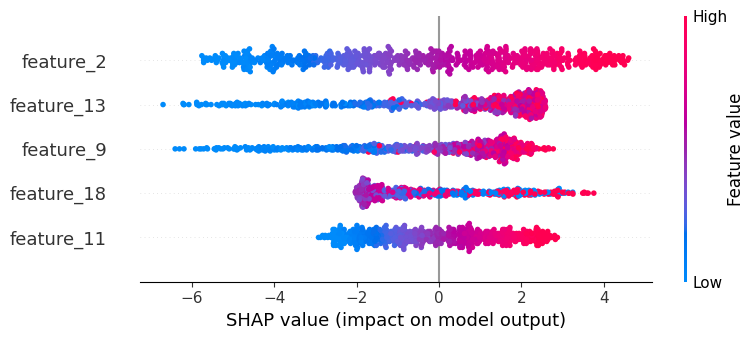

In [11]:
import matplotlib.pyplot as plt
import shap

top_5 = config.TOP_FEATURES
X_base = X_train[top_5].copy()

# Pass the callable .predict method + background data
explainer = shap.Explainer(sparse_pipe.predict, X_base)
shap_values = explainer(X_base)

plt.figure(figsize=(10, 5))
shap.summary_plot(shap_values, X_base, show=False)
plt.tight_layout()
plt.show()


In [55]:
report_df = pd.DataFrame({
    "Diagnostic Metric": [
        "R² Score",
        "RMSE",
        "MAE (Mean Abs Error)",
        "Mean Residual (Bias)",
        "Residual Std Dev",
        "Max Absolute Error",
    ],
    "Train": [
        f"{r2_score(y_train, y_train_pred):.5f}",
        f"{root_mean_squared_error(y_train, y_train_pred):.5f}",
        f"{mean_absolute_error(y_train, y_train_pred):.5f}",
        f"{train_res.mean():+.5f}",
        f"{train_res.std():.5f}",
        f"{np.abs(train_res).max():.5f}",
    ],
    "Validation": [
        f"{r2_score(y_val, y_val_pred):.5f}",
        f"{root_mean_squared_error(y_val, y_val_pred):.5f}",
        f"{mean_absolute_error(y_val, y_val_pred):.5f}",
        f"{val_res.mean():+.5f}",
        f"{val_res.std():.5f}",
        f"{np.abs(val_res).max():.5f}",
    ],
})

display(report_df.style.hide(axis="index"))


Diagnostic Metric,Train,Validation
R² Score,0.91626,0.89690
RMSE,1.49502,1.52140
MAE (Mean Abs Error),1.19731,1.22628
Mean Residual (Bias),-0.00000,-0.00840
Residual Std Dev,1.49619,1.52615
Max Absolute Error,4.95916,4.48434


## Prediction & Input Validation

This section tests model inference using `predict_from_df` and verifies input data integrity before generating predictions:

* **Valid input:** Runs inference on complete feature data and returns predictions as a `pandas.Series`.
* **Null-value check:** Validates required feature columns for missing values (`NaN`/`None`). If nulls are detected, inference is halted and a descriptive `ValueError` message is displayed instead of generating unreliable predictions.

In [19]:
sample_df = pd.DataFrame([{
    "feature_2": 0.5,
    "feature_9": -1.2,
    "feature_11": 0.8,
    "feature_13": 1.4,
    "feature_18": np.nan,
}])

try:
    predictions = predict_from_df(sample_df, model_path=config.MODEL_PATH)
    print(f"Prediction: {predictions.iloc[0]:.4f}")
except ValueError as e:
    print(e)

Invalid data: input contains null values in {'feature_18': 1}. Please provide complete data without nulls.


## What's Next?

* **Domain Error Tolerance:** While the model achieves strong statistical metrics, production viability depends on business-specific error thresholds. For example, a $\pm 4$ unit margin of error may be negligible for demand forecasting, but unacceptable when calibrating high-precision machinery.
* **Pre-Deployment Validation:** Package the model and run comprehensive integration and shadow tests in a staging environment before serving live predictions.
* **Code Modularization:** Refactor remaining notebook visualizations—particularly model evaluation and residual diagnostic plots—into reusable Python modules.
* **Model Simplification:** Benchmark `ElasticNetCV` directly as a unified alternative to the current two-stage `LassoCV` + `RidgeCV` pipeline to simplify hyperparameter tuning.
* **Domain-Driven Feature Ratios:** No transformations were applied at this stage, as appropriate imputation strategies depend heavily on the context of each variable. As a next step, once the domain context is better understood, missing model inputs could be imputed using the mean, median, or a constant value.